# Results: SAE features vs prompt embeddings, GPT-2 Small and Gemma 2 2B

Regenerate every number and figure with `make results` (runs this notebook in place, offline).
Everything is computed from the extraction cache (`data/experiments/`, built by
`uv run python -m eval.run_experiment extract`), the saved baselines and thresholds, and
`eval/results/experiment_runs.csv`; no model is loaded. The one exception is extraction overhead
(section 4), a timing measurement that needs the model: it is read from
`eval/results/latency_<profile>.json`, written by `uv run python -m eval.latency`.

Each scenario was replayed with **10 seeds** (0-9). With this many runs we describe how
**consistent** a difference is (for example "in 36 of 40 runs"); we do not claim statistical
significance. Thresholds are the saved ones (99th percentile of calibration windows) unless said
otherwise; `eval/results/experiment_tradeoff.png` compares the detectors at equal false-alarm
rates.

In [1]:
import sys
from pathlib import Path

from IPython.display import Image, display

cwd = Path.cwd().resolve()
ROOT = next(p for p in (cwd, *cwd.parents) if (p / "monitor").is_dir() and (p / "eval").is_dir())
sys.path.insert(0, str(ROOT))

from eval import analysis as a
from monitor.labels import get_label

RESULTS = ROOT / "eval" / "results"
rows = a.load_runs()
print(
    f"{len(rows)} runs; embedding rows identical under both profiles: {a.same_embedding_rows(rows)}"
)

/Users/sheddy/Desktop/Feature_monitor/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


200 runs; embedding rows identical under both profiles: True


## 1. Results table

Per series and scenario, across the 10 seeds: detection delay (requests after the shift starts
until the first alert) and false alarms (alerts per 1,000 requests on `normal_only`, the same
for every scenario of a series). "Near line" counts first alerts where normal traffic alone was
already at 95% of the threshold or more. Mean embedding distance does not depend on the
profile, so it appears once.

In [2]:
def fmt(v, digits=1):
    return "-" if v is None else f"{v:.{digits}f}"


print(
    f"{'series':<27}{'scenario':<22}{'det.':>6}{'delay mean':>11}{'sd':>7}{'min-max':>12}{'near':>6}"
    f"{'FA/1000 mean':>14}{'sd':>6}{'min-max':>10}{'FA runs':>8}"
)
for r in a.results_table(rows):
    print(
        f"{r['series']:<27}{r['scenario']:<22}{r['detected']:>6}{fmt(r['delay_mean']):>11}"
        f"{fmt(r['delay_sd']):>7}{fmt(r['delay_min'], 0) + '-' + fmt(r['delay_max'], 0):>12}"
        f"{r['near_line']:>6}{fmt(r['fa_mean'], 2):>14}{fmt(r['fa_sd'], 2):>6}"
        f"{fmt(r['fa_min'], 1) + '-' + fmt(r['fa_max'], 1):>10}{r['fa_runs']:>8}"
    )
print()
for profile in a.PROFILES:
    print(f"{a.LABELS[profile]}, seed by seed against embeddings: {a.head_to_head(rows, profile)}")

series                     scenario                det. delay mean     sd     min-max  near  FA/1000 mean    sd   min-max FA runs
SAE features, GPT-2 Small  medical_ramp           10/10      204.9   58.7     133-324     6          0.35  0.82   0.0-2.5    2/10
SAE features, GPT-2 Small  medical_nowhat_ramp    10/10      190.6   84.9      18-331     7          0.35  0.82   0.0-2.5    2/10
SAE features, GPT-2 Small  new_topic_ramp         10/10      286.0   88.2     193-407     6          0.35  0.82   0.0-2.5    2/10
SAE features, GPT-2 Small  injection_ramp         10/10      158.0   64.1      18-242     6          0.35  0.82   0.0-2.5    2/10
Embeddings, mean distance  medical_ramp           10/10      404.0  105.1     163-502     1          0.55  0.80   0.0-2.0    4/10
Embeddings, mean distance  medical_nowhat_ramp    10/10      404.8  103.8     165-501     1          0.55  0.80   0.0-2.0    4/10
Embeddings, mean distance  new_topic_ramp         10/10      448.9  104.2     174-544     

**What the table shows.**

- Every series detected every shift in all 10 seeds.
- Mean delay: GPT-2 SAE 158.0 to 286.0 requests, Gemma SAE 223.5 to 349.8, mean embedding distance 404.0 to 448.9, depending on the scenario. The SAE detector alerted first in 38 of 40 seed-by-seed comparisons on GPT-2 and 36 of 40 on Gemma.
- The spread is wide (standard deviations 59 to 113 requests), and the ranges overlap: the embedding detector's fastest runs (163 to 174, all seed 7) are faster than most SAE runs.
- False alarms on `normal_only`: GPT-2 SAE 0.35 per 1,000 requests (2 of 10 runs), Gemma SAE 0.15 (2 of 10), embeddings 0.55 (4 of 10). The largest single-run value, 2.5 per 1,000 (GPT-2 SAE, seed 1), is one score flickering around the threshold.
- "Near line": 6 or 7 of GPT-2's 10 SAE first alerts per scenario came when normal traffic alone was already at 95% of the threshold or more, against 1 or 2 for Gemma and 1 for embeddings. Gemma's minimum of 87 in every scenario is seed 3, where normal traffic alone crosses 10 requests later (see `docs/log.md`).

## 2. Figure 1: one run, both detectors

Medical questions, seed 0. Each score is divided by its own threshold, so both lines share one
axis and the dashed line at 1 is both alarm levels.

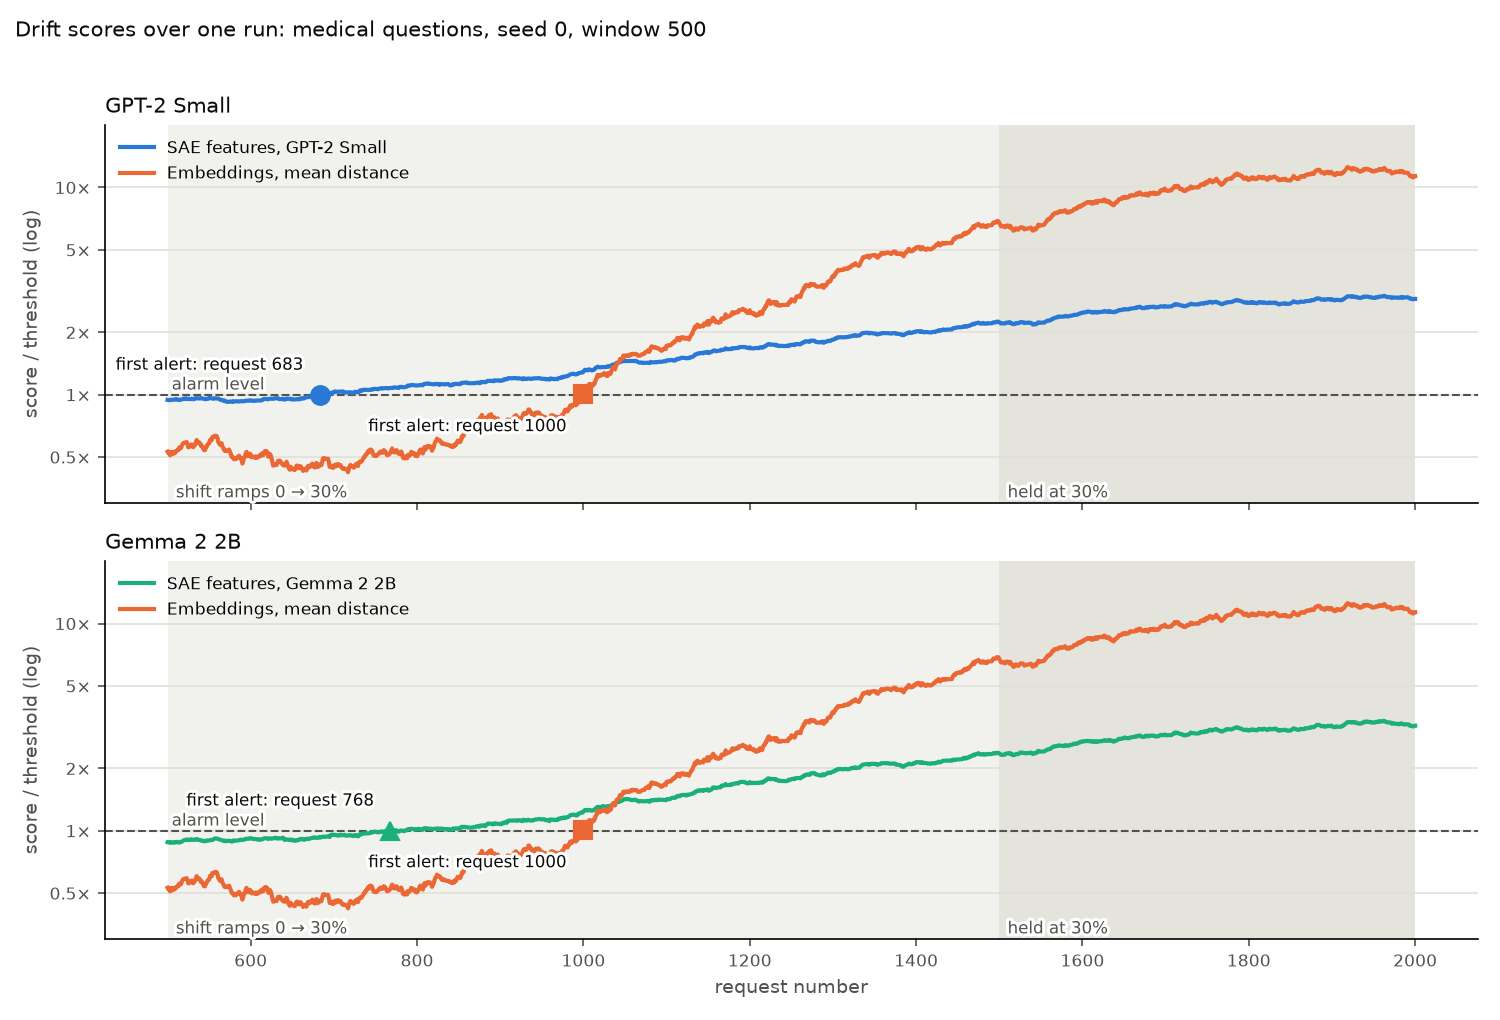

GPT-2 Small sae             first window: 0.94x, first alert: request 683, last window: 2.90x of threshold
GPT-2 Small embedding_mean  first window: 0.53x, first alert: request 1000, last window: 11.35x of threshold
Gemma 2 2B  sae             first window: 0.88x, first alert: request 768, last window: 3.22x of threshold
Gemma 2 2B  embedding_mean  first window: 0.53x, first alert: request 1000, last window: 11.35x of threshold


In [3]:
replays = {p: a.replay_one(p, "medical_ramp", 0) for p in a.PROFILES}
a.figure_scores(replays, "medical_ramp", 0, RESULTS / "fig1_scores.png")
display(Image(RESULTS / "fig1_scores.png"))
for profile, r in replays.items():
    for detector, scores in r["scores"].items():
        ratio = scores / r["thresholds"][detector]
        above = (ratio > 1).nonzero()[0]
        first = int(above[0]) + r["window_size"] if above.size else None
        print(
            f"{a.LABELS[profile]:<12}{detector:<16}first window: {ratio[0]:.2f}x, first alert: request {first}, "
            f"last window: {ratio[-1]:.2f}x of threshold"
        )

**In this run** the GPT-2 SAE detector first alerted at request 683 and the Gemma SAE detector at 768; mean embedding distance crossed at 1,000 (the same run for both, as it must be). The SAE scores started just under the line (0.94 and 0.88 of the threshold in the first full window) while the embedding score started at 0.53. Once the shift was large, the embedding score rose much further: 11.35 times its threshold in the last window, against 2.90 (GPT-2) and 3.22 (Gemma) for the SAE scores. So in this run the SAE detectors were closer to the line from the start and needed a smaller push, while the embedding detector separated a large shift more strongly.

## 3. Figure 2: detection delay by scenario

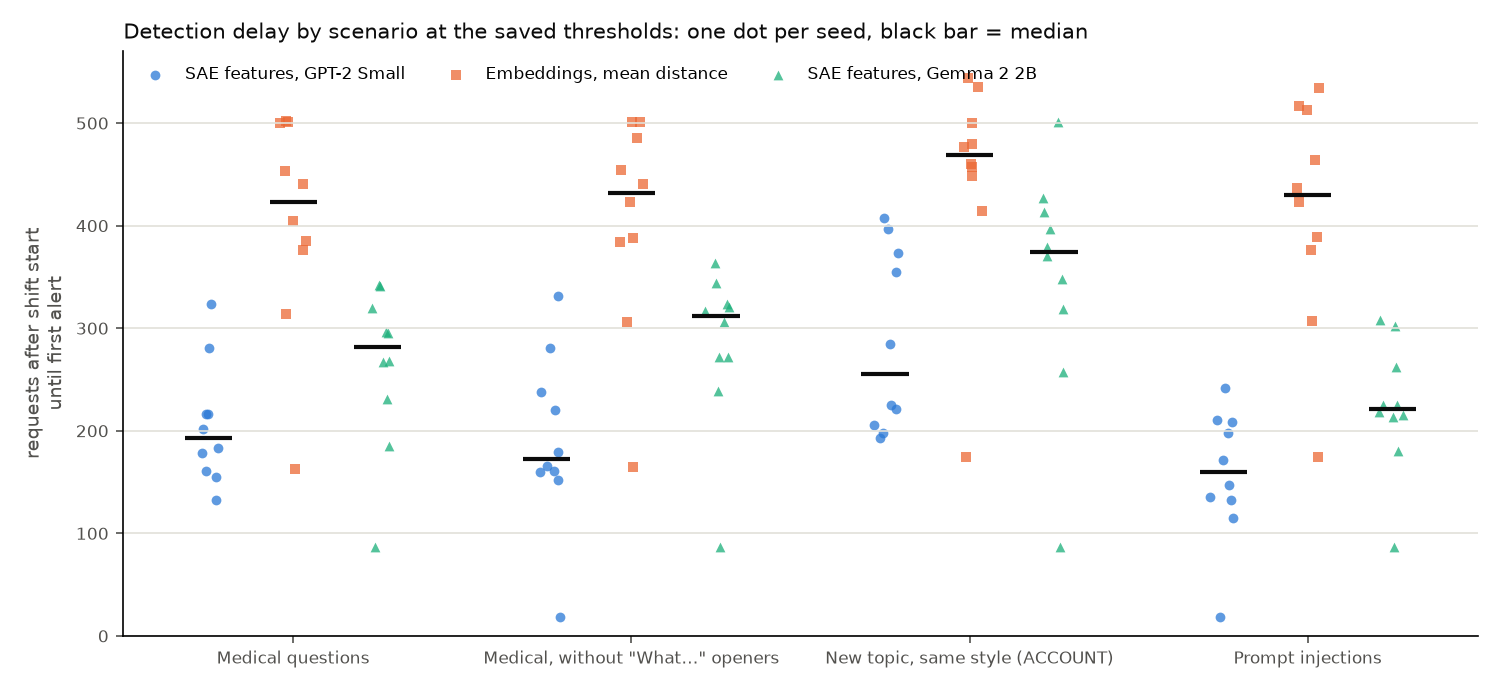

In [4]:
a.figure_delays(rows, RESULTS / "fig2_delays.png")
display(Image(RESULTS / "fig2_delays.png"))

**Across seeds** each SAE median is below the embedding median in every scenario, for both models, and Gemma's medians are above GPT-2's in every scenario. The new-topic scenario has the longest delays for all three series. The isolated low points are seed 7 for embeddings (163 to 174) and seed 3 for Gemma (87).

## 4. Extraction overhead per request

Measured by `eval/latency.py`: 100 sequential `/chat` requests with extraction on and 100 with it
off, on this Mac's CPU, each profile's full model generating up to 40 tokens. Not from the cache.

In [5]:
for profile in a.PROFILES:
    o = a.overhead(profile)
    if o is None:
        print(
            f"{a.LABELS[profile]}: no latency file; run FEATURE_MONITOR_PROFILE={profile} uv run python -m eval.latency"
        )
        continue
    print(
        f"{a.LABELS[profile]}: extraction p50 {o['extract_ms_p50']:.1f} ms, p95 {o['extract_ms_p95']:.1f} ms; "
        f"generation p50 {o['gen_ms_p50']:.0f} ms; total overhead {o['total_overhead_pct_p50']:+.1f}% at p50, "
        f"{o['total_overhead_pct_p95']:+.1f}% at p95 ({o['requests']} requests, checks passed: {o['checks_passed']})"
    )

GPT-2 Small: extraction p50 13.3 ms, p95 16.6 ms; generation p50 390 ms; total overhead +4.3% at p50, +18.5% at p95 (100 requests, checks passed: True)
Gemma 2 2B: extraction p50 207.7 ms, p95 351.2 ms; generation p50 3542 ms; total overhead +6.8% at p50, +15.4% at p95 (100 requests, checks passed: True)


**Overhead.** Extraction added a median of 13.3 ms to a GPT-2 request (+4.3% of total time at the median) and 207.7 ms to a Gemma request (+6.8%), next to median generation times of 390 ms and 3,542 ms. The p95 figures (+18.5% and +15.4%) are less reliable: generation time itself varied between the two 100-request runs (GPT-2 generation p95 472.8 ms with extraction on against 412.7 ms with it off), so part of that gap is not extraction.

## 5. Failure cases

Runs where the SAE detector alerted after the embedding detector, or never.

In [6]:
cases = a.failure_cases(rows)
for c in cases:
    print(
        f"{c['profile']:<11}{c['scenario']:<21}seed {c['seed']}: SAE at {c['sae_alert']:.0f}, embeddings at "
        f"{c['embedding_alert']:.0f}; normal traffic at the first alert: SAE {c['sae_ratio']:.3f}, "
        f"embeddings {c['embedding_ratio']:.3f} of threshold; embedding normal_only alerted first: "
        f"{c['embedding_normal_alerted_first']}"
    )

gemma2_2b  injection_ramp       seed 7: SAE at 718, embeddings at 674; normal traffic at the first alert: SAE 0.913, embeddings 0.980 of threshold; embedding normal_only alerted first: True
gemma2_2b  medical_nowhat_ramp  seed 7: SAE at 817, embeddings at 665; normal traffic at the first alert: SAE 0.850, embeddings 1.006 of threshold; embedding normal_only alerted first: True
gemma2_2b  medical_ramp         seed 7: SAE at 731, embeddings at 663; normal traffic at the first alert: SAE 0.926, embeddings 1.005 of threshold; embedding normal_only alerted first: True
gemma2_2b  new_topic_ramp       seed 7: SAE at 897, embeddings at 674; normal traffic at the first alert: SAE 0.891, embeddings 0.980 of threshold; embedding normal_only alerted first: True
gpt2_small medical_ramp         seed 7: SAE at 702, embeddings at 663; normal traffic at the first alert: SAE 0.945, embeddings 1.005 of threshold; embedding normal_only alerted first: True
gpt2_small new_topic_ramp       seed 7: SAE at 897

For two of them, the window that ended at the embedding detector's first alert: the features the
shift should move (most over-represented in the cached shift prompts against the baseline), how
far they had moved in that window, and what moved most by the per-feature drift test.

In [7]:
def show_case(profile, scenario, seed):
    case = next(
        c for c in cases if (c["profile"], c["scenario"], c["seed"]) == (profile, scenario, seed)
    )
    f = a.failure_features(case, top=6)
    print(
        f"{a.LABELS[profile]}, {scenario}, seed {seed}: window ending at request {case['embedding_alert']:.0f} "
        f"holds {f['shift_share']:.1%} shifted prompts; SAE score {f['sae_score_ratio']:.3f} of threshold"
    )
    with a.using_profile(profile):
        print("  should move (per 1,000: baseline -> shift pool -> this window):")
        for e in f["should_move"]:
            print(
                f"    #{e['feature']:<6}{e['baseline_rate']:7.1f} ->{e['shift_rate']:7.1f} ->{e['window_rate']:7.1f}  {get_label(e['feature'])[:60]}"
            )
        print("  moved most in this window (per 1,000: baseline -> window, adjusted p):")
        for d in f["moved_most"]:
            print(
                f"    #{d['feature']:<6}{d['baseline_rate']:7.1f} ->{d['window_rate']:7.1f}  p={d['adjusted_p']:.2g}  {get_label(d['feature'])[:60]}"
            )


show_case("gpt2_small", "new_topic_ramp", 7)
print()
show_case("gemma2_2b", "medical_ramp", 7)

GPT-2 Small, new_topic_ramp, seed 7: window ending at request 674 holds 0.8% shifted prompts; SAE score 0.963 of threshold
  should move (per 1,000: baseline -> shift pool -> this window):
    #10767     0.0 ->  573.3 ->    4.0  references to user accounts, specifically in the context of 
    #2712    146.3 ->  287.5 ->  126.0  references to personal ownership or possession
    #2607      8.3 ->  132.4 ->    6.0  instances of the phrase "sign up."
    #15259     5.0 ->  127.2 ->    4.0  instances of the word "sign" or similar terms indicating sym
    #11518     0.0 ->  117.0 ->    2.0  references to user experience and user-related terminology
    #11231    20.7 ->  123.4 ->   34.0  instances of the word "inform" and its derivatives in variou
  moved most in this window (per 1,000: baseline -> window, adjusted p):
    #23819    13.0 ->    2.0  p=0.86  references to legal charges and related legal processes
    #24216     2.0 ->   12.0  p=0.86  references to magazine or publication issu

Gemma 2 2B, medical_ramp, seed 7: window ending at request 663 holds 0.8% shifted prompts; SAE score 0.942 of threshold
  should move (per 1,000: baseline -> shift pool -> this window):
    #10976   326.3 ->  985.9 ->  358.0  occurrences of the word "The"
    #1033    404.7 ->  843.2 ->  454.0  HTML tags and their attributes related to web page structure
    #463     258.7 ->  668.2 ->  244.0  structured data and programming language syntax elements
    #15978   129.3 ->  497.8 ->  138.0  punctuation and the end of sentences
    #4246      3.3 ->  327.9 ->   12.0  questions or statements involving the verb "is."
    #7526    144.3 ->  450.0 ->  166.0  questions or inquiries, particularly those marked by questio
  moved most in this window (per 1,000: baseline -> window, adjusted p):
    #2474      2.0 ->   12.0  p=0.72  variations of the verb "make" in different forms and context
    #4494      2.0 ->   10.0  p=0.83  terms related to command lines and command execution
    #6392      8

The second kind of slowness: Gemma's SAE detector against GPT-2's. Two measurements, both from
the cache: where normal-only windows sit against each threshold (quantiles over all 10 seeds),
and the mean SAE score of 20 random normal windows with 0, 2, 5 and 10% of their prompts swapped
for shift prompts.

In [8]:
for profile in a.PROFILES:
    levels = a.normal_levels(profile)
    print(
        f"{a.LABELS[profile]}: normal_only windows / threshold, quantiles 50/90/99: "
        + "; ".join(f"{d} " + "/".join(f"{v:.3f}" for v in q.values()) for d, q in levels.items())
    )
    for scenario in a.PANELS:
        curve = a.mixing_curve(profile, scenario)
        print(
            f"   {scenario:<21}" + "  ".join(f"{share:.0%}: {v:.3f}" for share, v in curve.items())
        )

GPT-2 Small: normal_only windows / threshold, quantiles 50/90/99: sae 0.916/0.963/0.988; embedding_mean 0.625/0.821/0.984


   medical_ramp         0%: 0.898  2%: 1.010  5%: 1.158  10%: 1.446


   medical_nowhat_ramp  0%: 0.898  2%: 1.006  5%: 1.146  10%: 1.426


   new_topic_ramp       0%: 0.898  2%: 0.969  5%: 1.030  10%: 1.167


   injection_ramp       0%: 0.898  2%: 1.033  5%: 1.194  10%: 1.507


Gemma 2 2B: normal_only windows / threshold, quantiles 50/90/99: sae 0.881/0.934/0.989; embedding_mean 0.625/0.821/0.984


   medical_ramp         0%: 0.866  2%: 0.971  5%: 1.128  10%: 1.444


   medical_nowhat_ramp  0%: 0.866  2%: 0.972  5%: 1.104  10%: 1.430


   new_topic_ramp       0%: 0.866  2%: 0.944  5%: 1.014  10%: 1.188


   injection_ramp       0%: 0.866  2%: 1.046  5%: 1.246  10%: 1.682


**Failure cases: what the numbers show.** All 6 runs where the SAE detector alerted after embeddings are seed 7. In each, normal traffic alone was at 0.980 to 1.006 of the embedding threshold at its first alert, and the embedding detector's `normal_only` run for seed 7 had already alerted. The two windows examined held 0.8% shifted prompts. The features the shift should move had barely appeared (GPT-2, new topic: #10767, accounts, is in 573 of 1,000 shift prompts' top 20 but 4 per 1,000 in the window), and no feature changed significantly (adjusted p 0.72 or more).

For Gemma against GPT-2: normal-only windows sit lower against Gemma's threshold (median 0.881 against 0.916), and random normal windows score 0.866 against 0.898. Adding 2% shift prompts raised the medical score by about the same amount on both (+0.105 Gemma, +0.112 GPT-2), which took GPT-2 over the line (1.010) but not Gemma (0.971). At 10% shift the scores were similar (medical 1.444 against 1.446; injection higher for Gemma, 1.682 against 1.507).

**Hypotheses** (candidate explanations consistent with these numbers, not tested further):

1. *Hypothesis: the seed-7 cases are embedding false alarms, not SAE misses.* The embedding score was at its line from normal traffic alone and only 0.8% of the window was shifted, so the earlier embedding alert would likely have happened without the shift.
2. *Hypothesis: Gemma is slower mainly because its normal traffic sits further below its threshold, not because a shifted prompt moves its features less.* The per-prompt push at 2% and 10% shift is similar on both models; the starting level differs by about 0.03 to 0.035 of the threshold.
3. *Hypothesis: the new-topic shift is slowest because it keeps the customer-support style, so fewer features change.* It gives the smallest push at every share on both models (10%: 1.167 GPT-2, 1.188 Gemma, against 1.43 to 1.68 for the other scenarios). Its top shift features are about accounts and signing up, close to normal support traffic.

## 6. Conclusions

From the numbers above, at the saved thresholds and with 10 seeds per scenario:

1. Both SAE detectors alerted before mean embedding distance in most runs: 38 of 40 (GPT-2) and 36 of 40 (Gemma). All 6 exceptions are one seed, where the embedding score was already at its line from normal traffic.
2. They did so with fewer false alarms on normal traffic: 0.35 (GPT-2) and 0.15 (Gemma) against 0.55 alerts per 1,000 requests.
3. Gemma's SAE detector was slower than GPT-2's in every scenario on median, which the measurements attribute mostly to where normal traffic sits against each threshold.
4. Part of GPT-2's speed is proximity: most of its first alerts came with normal traffic already within 5% of the line. `eval/results/experiment_tradeoff.png` shows that at equal false-alarm rates the SAE detectors are still faster on both models.
5. Extraction cost 13.3 ms (GPT-2) and 207.7 ms (Gemma) per request at the median, 4.3% and 6.8% of request time on this Mac's CPU.

Limits: one layer per model, templated and synthetic datasets, ramp-shaped shifts only, first-crossing alerts, and Gemma at bfloat16 without a float32 check.